<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## פרוייקט סופי בלמידה מונחית חיזוקים
מגיש: מתן דיבה
207040171

**נושא הפרוייקט: חקר אלגוריתם MCTS (Monte Carlo Tree Search)  במשחק איקס עיגול מסלול ג**

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## תיאור הבעיה והגדרת ה-MDP

בפרוייקט זה נממש ונחקור את אלגוריתם MCTS ונבחן את ביצועיו במשחק איקס עיגול.
המשחק מוגדר כמשחק לשני שחקנים לשניהם ידיעה מלאה על הלוח , תורות מתחלפים וסכום אפס (יש רק מנצח אחד במשחק)

כדי לייצג את בעיית הלמידה בצורה פורמלית, נגדיר את רכיבי ה-(MDP) של הסביבה:

1. מרחב המצבים S:
מצב הלוח מיוצג על ידי מטריצה בגודל 3 על 3. כל תא בלוח יכול להכיל את אחד מהערכים הבאים:

*   0- עבור תא ריק
*   1- עבור סימן של שחקן 1 X
*   2- עבור סימן של שחקן 2 O


2. מרחב הפעולות A:
הפעולות האפשריות הן בחירת אינדקס של תא פנוי בלוח (מספר בין 0 ל-8, המייצג את המיקום בלוח השטוח). בכל תור, מרחב הפעולות החוקיות מצטמצם רק לתאים שערכם הנוכחי הוא 0.

3. מנגנון המעברים P: הסביבה היא דטרמיניסטית לחלוטין כלומר אין בה אלמנט של מזל. ברגע ששחקן בוחר פעולה חוקית, הלוח משתנה במדויק במיקום שנבחר לסימנו של אותו שחקן.

4. פונקציית התגמול R:
התגמול ניתן בסוף המשחק:

*   +1 אם שחקן 1 ניצח
*   -1 אם שחקן 2 ניצח
*   0 במקרה של תיקו או במהלך משחק שטרם הסתיים


תנאי סיום: המשחק מסתיים כאשר אחד השחקנים משיג שלישייה (שורה, עמודה או אלכסון) או כאשר הלוח מלא לחלוטין (תיקו).

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## בניית סביבת המשחק

תחילה נממש את מחלקת הסביבה TicTacToeEnv.
המחלקה תנהל את מצב הלוח, תאפשר לבצע מהלכים, תספק את רשימת המהלכים החוקיים ותבדוק האם המשחק הסתיים ובאיזו תוצאה.

In [1]:
import numpy as np

class TicTacToeEnv:
    def __init__(self):
        self.board = np.zeros(9, dtype=int) # לוח שטוח בגודל 9 (אינדקסים 0-8)
        self.current_player = 1 # שחקן 1 (X) מתחיל, שחקן 2 מיוצג על ידי 1- (O)

    def reset(self):
        """איפוס הלוח לתחילת משחק חדש"""
        self.board = np.zeros(9, dtype=int)
        self.current_player = 1
        return self.board.copy()

    def get_legal_actions(self):
        """החזרת רשימת האינדקסים של התאים הפנויים בלוח"""
        return np.where(self.board == 0)[0]

    def step(self, action):
        """ביצוע פעולה על הלוח על ידי השחקן הנוכחי"""
        if action not in self.get_legal_actions():
            raise ValueError(f"Action {action} is illegal on the current board!")

        # עדכון הלוח
        self.board[action] = self.current_player

        # בדיקה האם המשחק הסתיים
        is_terminal, winner = self._check_game_over()

        # קביעת ה-Reward
        reward = 0
        if is_terminal:
            if winner == 1:
                reward = 1
            elif winner == -1:
                reward = -1
            else:
                reward = 0

        # החלפת תור השחקן (אם 1 הופך ל-1-, אם 1- הופך ל-1)
        self.current_player = -self.current_player

        return self.board.copy(), reward, is_terminal, {"winner": winner}

    def _check_game_over(self):
        """בדיקה פנימית האם יש מנצח או תיקו"""
        # הגדרת כל השלשות האפשריות לניצחון (שורות, עמודות ואלכסונים)
        winning_combinations = [
            [0, 1, 2], [3, 4, 5], [6, 7, 8], # שורות
            [0, 3, 6], [1, 4, 7], [2, 5, 8], # עמודות
            [0, 4, 8], [2, 4, 6]             # אלכסונים
        ]

        for combo in winning_combinations:
            board_slice = self.board[combo]
            if np.all(board_slice == 1):
                return True, 1  # שחקן 1 ניצח
            if np.all(board_slice == -1):
                return True, -1 # שחקן 2 ניצח

        # אם אין שלשה פנויה ואין תאים ריקים - המשחק נגמר בתיקו
        if len(self.get_legal_actions()) == 0:
            return True, 0 # תיקו

        return False, None # המשחק נמשך

    def render(self):
        """הדפסה ויזואלית של הלוח בצורה נוחה לעין"""
        symbols = {0: '.', 1: 'X', -1: 'O'}
        board_3x3 = self.board.reshape(3, 3)
        for row in board_3x3:
            print(" ".join([symbols[cell] for cell in row]))
        print("-" * 5)

    def clone(self):
        """פונקציה קריטית עבור סימולציות MCTS - מאפשרת להעתיק את מצב הסביבה הנוכחי במדויק"""
        env_copy = TicTacToeEnv()
        env_copy.board = self.board.copy()
        env_copy.current_player = self.current_player
        return env_copy

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**אתחול המחלקה ואיפוס הלוח**

__init__ (אתחול): מגדיר את שני משתני המצב הבסיסיים של המשחק:

*   self.board: לוח המשחק מיוצג כמערך חד-ממדי (שטוח) בגודל 9 תאים של NumPy. הערך 0
מייצג תא ריק.

*   self.current_player: השחקן שתורו לשחק כרגע. שחקן 1 הוא איקס (X) והוא זה שמתחיל, ושחקן 1- הוא עיגול (O).

reset (איפוס): מנקה את הלוח (מחזיר את כל 9 התאים ל-0), קובע מחדש ששחקן 1 מתחיל, ומחזיר עותק של הלוח הריק.</p>
</div>

In [2]:
 # def get_legal_actions(self):
  #      """החזרת רשימת האינדקסים של התאים הפנויים בלוח"""
   #     return np.where(self.board == 0)[0]

    # def step(self, action):
      #  """ביצוע פעולה על הלוח על ידי השחקן הנוכחי"""
       # if action not in self.get_legal_actions():
        #    raise ValueError(f"Action {action} is illegal on the current board!")

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**קבלת מהלכים חוקיים ושכפול סביבה**

אנחנו אומרים לשחקן/לסוכן אילו משבצות בלוח עדיין פנויות ומותר לשחק בהן בתור הנוכחי:

*   self.board == 0 יוצר מערך של ערכים בוליאניים (True/False), שבו יש True רק במיקומים שבהם יש 0 (כלומר משבצת ריקה).

*   np.where(...) מוצא את האינדקסים (המיקומים בין 0 ל-8) שקיבלו את הערך True.

*   הסיומת [0] נחוצה משום ש-np.where מחזירה טאפל (Tuple) של מערכים, והאינדקס [0] שולף מתוכו ישירות את מערך האינדקסים החד-ממדי שמעניין אותנו.

**תחילת ביצוע צעד ובדיקת תקינות**

מוודאים שהשחקן או הסוכן לא מנסים "לרמות" או לבצע טעות ולשים סימן במשבצת שכבר תפוסה על ידי X או O.

*   השחקן מעביר לפונקציה step את הפעולה המבוקשת (action - מספר בין 0 ל-8).

*   השורה if action not in self.get_legal_actions(): בודקת האם המהלך הזה בכלל נמצא ברשימת המהלכים החוקיים שקיבלנו מהפונקציה הקודמת.

*   במידה והמהלך אינו חוקי (למשל, מנסים לסמן משבצת שכבר תפוסה), התוכנית עוצרת מיד וזורקת שגיאה מסוג ValueError עם הסבר ברור כדי למנוע שיבוש של מצב הלוח.


</p>
</div>

In [3]:
   # Updating board
   #     self.board[action] = self.current_player

        # Checking if the game is over
    #    is_terminal, winner = self._check_game_over()

        # Determing the reward
     #   reward = 0
      #  if is_terminal:
       #     if winner == 1:
        #        reward = 1
         #   elif winner == -1:
          #      reward = -1
           # else:
            #    reward = 0

        # Switching Player turns
       # self.current_player = -self.current_player

        #return self.board.copy(), reward, is_terminal, {"winner": winner}

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**עדכון הלוח וזיהוי סיום המשחק**

 self.board[action] = self.current_player: אנחנו ניגשים לאינדקס שנבחר בלוח השטוח (ערך בין 0 ל-8) ומציבים שם את הערך של השחקן הנוכחי (1 עבור X או 1- עבור O).

is_terminal, winner = self._check_game_over(): מיד לאחר הנחת הסימן החדש, אנחנו קוראים לפונקציה הפנימית שבודקת האם המהלך הזה הוביל לסיום המשחק. היא מחזירה שני ערכים:

1. is_terminal: משתנה בוליאני (True או False) שמסמן האם המשחק נגמר (בגלל ניצחון או תיקו).
2. winner: מזהה השחקן שניצח (1, 1-) או None אם אין מנצח.


**חישוב התגמול**

להחזיר פידבק מספרי על תוצאת הצעד (התגמול של ה-MDP).
כברירת מחדל, ה-reward מוגדר כ-0.
רק אם המשחק הגיע לסיומו (if is_terminal), אנחנו קובעים את הערך:
1. אם שחקן 1 (X) ניצח (winner == 1) -> ה-reward יהיה 1.
2. אם שחקן 2 (O) ניצח (winner == -1) -> ה-reward יהיה 1-.
3. במצב של תיקו -> ה-reward נשאר 0.

**החלפת תור השחקן**


אם השחקן הנוכחי היה 1 (X), השורה מבצעת 1- והתור עובר ל-O.
אם השחקן הנוכחי היה 1- (O), מינוס כפול מינוס הופך לפלוס ((1-) - = 1) והתור חוזר ל-X.

**החזרת הערכים**

הפונקציה מחזירה טאפל (Tuple) המכיל ארבעה אלמנטים:
1. self.board.copy(): עותק של הלוח המעודכן (אנחנו מחזירים העתק copy כדי שהמשתמש מחוץ לסביבה לא יוכל לשנות בטעות את מערך הלוח המקורי של המחלקה).
2. reward: התגמול שחושב על הצעד הזה.
3. is_terminal: האם המשחק הסתיים.
4. {"winner": winner}: מילון מידע נוסף (info dictionary) המכיל את מזהה המנצח (אם קיים).
</p>
</div>

In [4]:
  # def _check_game_over(self):
   #     """בדיקה פנימית האם יש מנצח או תיקו"""
        # הגדרת כל השלשות האפשריות לניצחון (שורות, עמודות ואלכסונים)
    #    winning_combinations = [
     #       [0, 1, 2], [3, 4, 5], [6, 7, 8], # Rows
      #      [0, 3, 6], [1, 4, 7], [2, 5, 8], # Columns
       #     [0, 4, 8], [2, 4, 6]             # Diagonals
        #]

        #for combo in winning_combinations:
         #   board_slice = self.board[combo]
          #  if np.all(board_slice == 1):
           #     return True, 1  # Player 1 won
            #if np.all(board_slice == -1):
             #   return True, -1 # Player 2 won
        # אם אין שלשה פנויה ואין תאים ריקים - המשחק נגמר בתיקו
        #if len(self.get_legal_actions()) == 0:
         #   return True, 0 # Tie

        #return False, None # Game continues


<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**הגדרת השלשות המנצחות**

הגדרת השילובים של 3 משבצות על הלוח השטוח (באינדקסים 0 עד 8) שמייצגים רצף של שורה, עמודה או אלכסון.

[0, 1, 2], [3, 4, 5], [6, 7, 8] הן שלוש השורות האופקיות.

[0, 3, 6], [1, 4, 7], [2, 5, 8] הן שלוש העמודות האנכיות.

[0, 4, 8], [2, 4, 6] הם שני האלכסונים.

**בדיקת מנצח בעזרת פרוסות לוח**

*   לולאת ה-for: רצה ועוברת אחת-אחת על כל אחת מ-8 השלשות שהוגדרו למעלה.

*   board_slice = self.board[combo]:  שולפים מהלוח "פרוסה" (Slice) המכילה רק את שלושת הערכים שנמצאים באינדקסים של השלשה הנוכחית.

*   np.all(board_slice == 1): פונקציית np.all בודקת האם כל האיברים בפרוסה שווים ל-1. אם כן, זה אומר ששחקן 1 (X) הצליח להשלים את השלשה הזו, ולכן הפונקציה מחזירה מיד True (המשחק נגמר) ו-1 (המנצח).

*   np.all(board_slice == -1): באותו אופן, בודק האם כל שלושת המיקומים מכילים 1-. אם כן, שחקן 2 (O) השלים שלשה, והפונקציה מחזירה True ו-1-.

**בדיקת תיקו או המשך המשחק**

*   בדיקת התיקו (len(...) == 0): אם הקוד עבר על כל 8 השלשות ולא מצא מנצח, הוא בודק האם נשארו מהלכים חוקיים פנויים בלוח. אם אורך רשימת המהלכים החוקיים הוא 0 (הלוח מלא לחלוטין), המשחק מסתיים בתיקו, והפונקציה מחזירה True (המשחק נגמר) ו-0 (תוצאת תיקו).

*   המשך המשחק (return False, None): אם אין מנצח והלוח עדיין לא מלא, המשחק נמשך כרגיל. הפונקציה מחזירה False (המשחק לא נגמר) ו-None (אין עדיין מנצח).

</p>
</div>

In [5]:
 #def render(self):
  #      """הדפסה ויזואלית של הלוח בצורה נוחה לעין"""
   #     symbols = {0: '.', 1: 'X', -1: 'O'}
    #    board_3x3 = self.board.reshape(3, 3)
     #   for row in board_3x3:
      #      print(" ".join([symbols[cell] for cell in row]))
      #  print("-" * 5)

    #def clone(self):
     #   """פונקציה קריטית עבור סימולציות MCTS - מאפשרת להעתיק את מצב הסביבה הנוכחי במדויק"""
      #  env_copy = TicTacToeEnv()
       # env_copy.board = self.board.copy()
        #env_copy.current_player = self.current_player
        #return env_copy

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**הדפסת הלוח**

הצגת הלוח בצורה גרפית נוחה וקריאה.

*   symbols = {0: '.', 1: 'X', -1: 'O'}: מילון (Dictionary) פשוט שממפה את הייצוג המספרי של ה-MDP לייצוג גרפי: 0 הופך לנקודה (תא ריק), 1 הופך ל-X ו-1- הופך ל-O.

*   board_3x3 = self.board.reshape(3, 3): מכיוון שהלוח שמור כמערך שטוח של 9 תאים, אנחנו משתמשים בפונקציה reshape של NumPy כדי לסדר אותו זמנית כמטריצה דו-ממדית בגודל $3 \times 3$ (3 שורות ו-3 עמודות).

*   for row in board_3x3: לולאה שעוברת שורה-שורה במטריצה החדשה.

*   " ".join([symbols[cell] for cell in row]):קטע קוד (List Comprehension) שעובר על שלושת המספרים בשורה הנוכחית, מחליף כל מספר בסימן המתאים לו מהמילון (למשל, הופך את [1, 0, -1] ל-['X', '.', 'O']), ומחבר אותם למחרוזת אחת עם רווחים ביניהם.

*   print("-" * 5): מדפיס קו מפריד של 5 מקפים מתחת ללוח כדי שנדע היכן מסתיים המצב הנוכחי בטרמינל.

**שכפול הסביבה לסימולציה**

יצירת העתק עצמאי לחלוטין של המשחק.

*   env_copy = TicTacToeEnv():  מקימים אובייקט סביבה חדש לגמרי מאותה מחלקה.

*   env_copy.board = self.board.copy(): מעתיקים את מערך הלוח הנוכחי אל הסביבה  החדשה. – אם לא היינו משתמשים ב- copy(), פייתון היה מעביר רק מצביע (Reference) לאותו מערך, וכל שינוי בלוח המשוכפל היה משנה ישירות גם את הלוח האמיתי של המשחק.

*   env_copy.current_player = self.current_player: מעתיק גם את התור של מי שצריך לשחק כרגע (כדי שהסימולציה תמשיך בדיוק מהנקודה הנכונה).

*   return env_copy: מחזיר את אובייקט הסביבה המשוכפל והמבודד.

</p>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>


### בדיקות תקינות לסביבה
לפני שנממש את סוכני הלמידה והחיפוש, נבצע בדיקת תקינות קצרה לסביבה שיצרנו כדי לוודא שניהול התורות, זיהוי המהלכים החוקיים ומנגנון הניצחון עובדים כמצופה.


</p>
</div>

In [6]:
# יצירת סביבה ובדיקת מצב ראשוני
test_env = TicTacToeEnv()
print("לוח התחלתי ריק:")
test_env.render()
print(f"השחקן הנוכחי (1 = X, -1 = O): {test_env.current_player}")
print(f"מהלכים חוקיים זמינים: {test_env.get_legal_actions()}")

# ביצוע מהלך במרכז הלוח (אינדקס 4)
print("\n--- מבצעים מהלך באינדקס 4 ---")
board, reward, is_terminal, info = test_env.step(4)
test_env.render()
print(f"השחקן הבא בתור: {test_env.current_player}")
print(f"מהלכים חוקיים נותרים: {test_env.get_legal_actions()}")

לוח התחלתי ריק:
. . .
. . .
. . .
-----
השחקן הנוכחי (1 = X, -1 = O): 1
מהלכים חוקיים זמינים: [0 1 2 3 4 5 6 7 8]

--- מבצעים מהלך באינדקס 4 ---
. . .
. X .
. . .
-----
השחקן הבא בתור: -1
מהלכים חוקיים נותרים: [0 1 2 3 5 6 7 8]


In [7]:
# איפוס מחדש ויצירת רצף מהלכים שמוביל לניצחון של X
test_env.reset()
test_env.step(0) # X מציב ב-0
test_env.step(3) # O מציב ב-3
test_env.step(1) # X מציב ב-1
test_env.step(4) # O מציב ב-4
board, reward, is_terminal, info = test_env.step(2) # X מציב ב-2 ומנצח!

print("מצב הלוח בסיום רצף הניצחון:")
test_env.render()
print(f"האם המשחק הסתיים? {is_terminal}")
print(f"התגמול (Reward) שהתקבל: {reward}")
print(f"מידע סופי (Info): {info}")

מצב הלוח בסיום רצף הניצחון:
X X X
O O .
. . .
-----
האם המשחק הסתיים? True
התגמול (Reward) שהתקבל: 1
מידע סופי (Info): {'winner': 1}


<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## בניית שחקני הבייסליין

כעת, אחרי שהבנו את חוקי העולם שלנו, וכדי להוכיח שהMCTS שלנו באמת לומד ומתפקד בצורה חכמה אנחנו חייבים יריבם פשוטים שישחקו מולו.

נממש 2 סוכני בייסליין בסיסיים:


1.   סוכן אקראי- סוכן ללא כל אסטרטגיה הבוחר בכל תור פעולה חוקית באופן אקראי מתוך התאים הפנויים.
2.   סוכן חמדן (חוסם)- סוכן המבוסס על חוקים קבועים מראש. הוא בודק בצורה חמדנית האם יש לו מהלך שמנצח את המשחק באופן מיידי באותו תור. אם לא, הוא בודק האם ליריב יש מהלך שמנצח בתור הבא, ואם כן - הוא חוסם אותו. אם אף אחד מהתנאים לא מתקיים, הוא בוחר מהלך אקראי.


</p>
</div>

In [8]:
import random

class RandomAgent:
    def __init__(self, player_sign):
        self.player_sign = player_sign # 1 עבור איקס, 1- עבור עיגול

    def select_action(self, env):
        """בחירת מהלך אקראי לחלוטין מתוך המהלכים החוקיים"""
        legal_actions = env.get_legal_actions()
        return random.choice(legal_actions)


class GreedyAgent:
    def __init__(self, player_sign):
        self.player_sign = player_sign

    def select_action(self, env):
        legal_actions = env.get_legal_actions()

        # חוק 1: בדיקה האם יש מהלך שמביא לניצחון מיידי שלי
        for action in legal_actions:
            env_clone = env.clone()
            _, _, is_terminal, info = env_clone.step(action)
            if is_terminal and info["winner"] == self.player_sign:
                return action

        # חוק 2: בדיקה האם יש מהלך שמביא לניצחון מיידי של היריב - ואז לחסום אותו
        opponent_sign = -self.player_sign
        for action in legal_actions:
            env_clone = env.clone()
            # נדמה מה קורה אם היריב משחק במיקום הזה
            env_clone.current_player = opponent_sign
            _, _, is_terminal, info = env_clone.step(action)
            if is_terminal and info["winner"] == opponent_sign:
                return action

        # חוק 3: אם אין מהלך מנצח או חוסם, בחר מהלך אקראי
        return random.choice(legal_actions)

In [9]:
#import random

#class RandomAgent:
 #   def __init__(self, player_sign):
  #      self.player_sign = player_sign # 1 for player X, -1 for player O

   # def select_action(self, env):
    #    """בחירת מהלך אקראי לחלוטין מתוך המהלכים החוקיים"""
     #   legal_actions = env.get_legal_actions()
      #  return random.choice(legal_actions)

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**האתחול**

הגדרת השחקן האקראי מיהו ואיזה סימן הוא מייצג על הלוח.
בעת יצירת הסוכן, אנחנו מעבירים לו את הפרמטר player_sign.

הערך יהיה 1 אם הסוכן משחק בתור איקס (X), או 1- אם הוא משחק בתור עיגול (O). הערך הזה נשמר במשתנה המחלקה self.player_sign לשימוש עתידי.

**בחירת המהלך**

החזרת מהלך חוקי יחיד שנבחר בצורה אקראית לחלוטין. זו הפונקציה הראשית שהמשחק קורא לה בכל פעם שזהו תורו של הסוכן הזה לשחק.

*   legal_actions = env.get_legal_actions(): הסוכן פונה לאובייקט הסביבה שהועבר לו (env) ומבקש את רשימת האינדקסים של המשבצות הפנויות שנותרו על הלוח באותו הרגע (באמצעות הפונקציה שניתחנו בסגמנט הקודם).

*   random.choice(legal_actions): משתמשים בפונקציה choice מתוך ספריית random המובנית של פייתון. הפונקציה הזו מקבלת את רשימת המיקומים החוקיים, בוחרת מתוכה אינדקס אחד באקראי בהסתברות אחידה (לכל משבצת פנויה יש סיכוי שווה להיבחר), ומחזירה אותו כפעולה הנבחרת לביצוע.

</p>
</div>

In [10]:
#class GreedyAgent:
 #   def __init__(self, player_sign):
  #      self.player_sign = player_sign

   # def select_action(self, env):
    #    legal_actions = env.get_legal_actions()

        # חוק 1: בדיקה האם יש מהלך שמביא לניצחון מיידי שלי
     #   for action in legal_actions:
      #      env_clone = env.clone()
       #     _, _, is_terminal, info = env_clone.step(action)
        #    if is_terminal and info["winner"] == self.player_sign:
         #       return action

        # חוק 2: בדיקה האם יש מהלך שמביא לניצחון מיידי של היריב - ואז לחסום אותו
        #opponent_sign = -self.player_sign
        #for action in legal_actions:
         #   env_clone = env.clone()
            # נדמה מה קורה אם היריב משחק במיקום הזה
          #  env_clone.current_player = opponent_sign
           # _, _, is_terminal, info = env_clone.step(action)
           # if is_terminal and info["winner"] == opponent_sign:
            #    return action

        # חוק 3: אם אין מהלך מנצח או חוסם, בחר מהלך אקראי
        # return random.choice(legal_actions)

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**האתחול והחוק הראשון – בדיקת ניצחון עצמי**

__init__: מגדיר את הסימן של הסוכן על הלוח (self.player_sign יקבל 1 עבור X או 1- עבור O).

legal_actions: שולף את רשימת המשבצות הפנויות שיש כרגע על הלוח האמיתי.

חוק 1 (תקיפה):

*   הסוכן רץ בלולאה על כל הפעולות החוקיות האפשריות.

*   עבור כל פעולה, הוא יוצר עותק נפרד של הסביבה באמצעות env.clone().

*   הוא מבצע את המהלך "בדמיון" על גבי העותק המשוכפל בעזרת env_clone.step(action).

*   הוא בודק: אם המהלך הזה הוביל לסיום המשחק (is_terminal) וגם השחקן שניצח הוא הוא עצמו (info["winner"] == self.player_sign), הוא מחזיר מיד את הצעד הזה. אין צורך להמשיך לבדוק חוקים אחרים – זה מהלך שמביא לניצחון מיידי בתור הנוכחי!

**החוק השני – מניעת ניצחון של היריב (חסימה)**

opponent_sign = -self.player_sign: מגדיר את הסימן של היריב. אם הסוכן הוא X (ערך 1), היריב הוא O (ערך 1-), ולהפך.

חוק 2 (הגנה):

*   אם חוק 1 לא מצא מהלך מנצח, הסוכן עובר לבדוק אם יש סכנת הפסד מיידית בתור הבא של היריב.

*   הוא עובר בלולאה על כל המהלכים החוקיים.

*   עבור כל מהלך, הוא משכפל את הלוח הנוכחי ומשנה בהעתק את תור השחקן באופן ידני לסימן של היריב (env_clone.current_player = opponent_sign).

*   הוא מריץ את הצעד הזה ומדמה שהיריב בחר לשחק שם.

*   אם הצעד גורם למשחק להסתיים והיריב מנצח (info["winner"] == opponent_sign), הסוכן מבין שהוא חייב לחסום את הנקודה הזו. הוא מחזיר את הצעד הזה מיד כדי להציב שם את הסימן שלו במשחק האמיתי ולמנוע מהיריב לנצח.


**החוק השלישי – ברירת מחדל אקראית**

חוק 3 (משחק שוטף):

*   אם הסוכן סיים לסרוק את כל המהלכים האפשריים, וגילה שאין לו מהלך ניצחון מיידי וגם אין ליריב מהלך ניצחון מיידי שצריך לחסום – הוא פשוט פונה לברירת המחדל.

*   הוא בוחר באקראי לחלוטין אחד מהמהלכים החוקיים מתוך הרשימה, ומחזיר אותו.

</p>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

##  אלגוריתם Monte Carlo Tree Search (MCTS)

בפרק זה נממש את לב המערכת - סוכן מבוסס תכנון וחיפוש בעץ (MCTS). האלגוריתם אינו דורש ידע מוקדם על הסתברויות המעבר של הסביבה, אלא לומד אותן ומבצע תכנון אונליין על ידי הרצת סימולציות מהמצב הנוכחי.

האלגוריתם אומר: "בוא נריץ כמה מאות משחקים מהירים 'בדמיון' (סימולציות). בכל סימולציה נתחיל מהמצב הנוכחי שהוא השורש, נבחר מהלכים שנראים לנו מבטיחים, נשחק באקראי מהר מאוד עד סוף המשחק, ונראה מי מנצח. הצעד האמיתי שנבחר לעשות על הלוח יהיה המהלך שהוביל להכי הרבה ניצחונות בסימולציות האלו".
בכל פעם שהסוכן צריך לבצע מהלך, הוא מריץ N סימולציות (למשל 100 סימולציות). כל סימולציה מורכבת מ-4 שלבים מדויקים:

1. **Selection:** מתחילים מצומת השורש (מצב המשחק האמיתי כרגע) ויורדים למטה בעץ, דרך צמתים (מהלכים) שכבר חקרנו בעבר.
בגרסה הבסיסית והפשוטה, אנחנו בוחרים בצורה חמדנית (Greedy) את הילד שיש לו את אחוז הניצחונות הכי גבוה עד כה ($\frac{Q}{N}$), כאשר $Q$ הוא סך הניקוד שקיבלנו מהצומת הזה, ו-$N$ הוא מספר הביקורים בו.
ממשיכים לרדת בעץ עד שאנחנו מגיעים לצומת שיש לו מהלכים חוקיים שעדיין לא פתחנו להם צומת ילד משלהם בעץ (כלומר, מהלכים שטרם ניסינו אפילו פעם אחת "בדמיון").
(בעזרת כלי בינה מלאכותית מצאתי את הנוסחה שנקראת UCB ולהלן הנוסחה:$$\text{UCB} = \frac{Q_i}{N_i} + c \times \sqrt{\frac{\ln(N_{\text{parent}})}{N_i}}$$
כאשר:
*   החלק השמאלי ($\frac{Q_i}{N_i}$): מייצג Exploitation (ניצול הצלחות) – מהלכים שהביאו לאחוז ניצחונות גבוה בעברת כלומר הוא מייצג את אחוז הניצחונות הממוצע (או התשואה הממוצעת) של המהלך הזה. ככל שהאיבר הזה גבוה יותר, זה אומר שהמהלך הזה הניב יותר ניצחונות בסימולציות, ולכן כדאי לנו להמשיך לבחור בו (לנצל אותו).

*   החלק הימני: מייצג Exploration (חקר המרחב) – נותן בונוס לצמתים שכמעט ולא ביקרנו בהם ($N_i$ קטן מאוד ביחס ל-$N_{\text{parent}}$). $N_{\text{parent}}$ (מספר הביקורים בצומת האב): כמה סימולציות עברו בסך הכל דרך צומת האב (הצומת שממנו אנחנו מנסים לבחור לאיזה ילד לרדת). $N_i$ (מספר הביקורים בצומת הילד הנוכחי): מופיע כאן בתוך המחלק (במכנה). השבר כולו $\sqrt{\frac{\ln(N_{\text{parent}})}{N_i}}$: * ככל שאנחנו מבקרים בצומת מסוים פחות פעמים ($N_i$ קטן), המכנה קטן ולכן השבר כולו גדל ומעניק לצומת הזה "בונוס חקר" גבוה מאוד.


*    הפרמטר $c$ שולט באיזון ביניהם (בדרך כלל נקבע ל-$\sqrt{2}$). אם נקבע $c$ גבוה מאוד – האלגוריתם יעדיף לחקור צמתים חדשים ולא מוכרים (יעשה המון Exploration). אם נקבע $c = 0$ – האלגוריתם יתעלם לחלוטין מחקר ויהפוך לחמדן (Greedy) לחלוטין; הוא יבחר רק את המהלך עם ממוצע הניצחונות הגבוה ביותר כרגע. כלומר הוא משמש "משקל" לקביעת רמת הנטייה לחקר. אנחנו עוצרים את הירידה ברגע שהגענו לצומת שיש לו פעולות חוקיות שעדיין לא פתחנו להן צומת ילד בעץ.

2. **Expansion:** הגענו לצומת שיש לו מהלכים פנויים שטרם ניסינו. אנחנו בוחרים מהלך אחד כזה באקראי, יוצרים עבורו צומת ילד חדש בעץ ומחברים אותו. עכשיו העץ שלנו גדל בצעד אחד נוסף.

3. **Simulation (Rollout):** מהצומת החדש שזה עתה יצרנו, אנחנו מריצים משחק וירטואלי מהיר מאוד עד הסוף שלו.
משתמשים במדיניות ברירת מחדל , שהיא בדרך כלל משחק אקראי לחלוטין. שני הצדדים משחקים באקראי בשניות עד שהמשחק מסתיים בתיקו, ניצחון או הפסד. בשלב זה לא מייצרים צמתים חדשים בעץ – זהו רק משחק וירטואלי מהיר בזיכרון.

4. **Backpropagation:** המשחק הווירטואלי הסתיים וקיבלנו תוצאה (למשל: X ניצח, שזה 1+ עבורנו). ועכשיו מעדכנים את המידע החדש הזה לאורך כל המסלול שעברנו בסימולציה הנוכחית. עושים זאת באמצעות טיפוס מהילד החדש חזרה למעלה עד שמגיעים לשורש ובכל צומת בדרך מעלים את מונה הביקורים ב-1, ומוסיפים את תוצאת המשחק לערך הניקוד.

אחרי שסיימנו להריץ את כל 100 הסימולציות האלו, יש לנו עץ קטן בזיכרון שבו לכל מהלך אפשרי מהשורש יש מונים של "כמה פעמים ביקרנו בו" ($N$) ו"כמה ניצחונות חזרו ממנו" ($Q$).הסוכן בוחר לבצע במשחק האמיתי את המהלך שהוביל לצומת הילד עם מספר הביקורים ($N$) הגבוה ביותר, כי זהו המהלך שנחקר הכי הרבה פעמים והוכח כיציב והבטוח ביותר.

כדי לממש את זה אנחנו צריכים שני רכיבים:

1. מחלקה בשם MCTSNode שמייצגת צומת בודד בעץ ושומרת על המצבים, המונים, הילדים וההורה שלו.
2. מחלקה בשם MCTSAgent שמכילה את הלולאה הראשית ואת ארבעת השלבים.



</p>
</div>

In [11]:
class MCTSNode:
    def __init__(self, env, parent=None, action_taken=None):
        self.env = env.clone() # העתק קפוא של מצב הסביבה בצומת זה
        self.parent = parent
        self.action_taken = action_taken # הפעולה שהובילה לצומת זה
        self.children = {} # מילון שממפה בין פעולה לצומת הילד שלה

        self.visits = 0 # N
        self.value = 0.0 # Q

        # רשימת הפעולות החוקיות שטרם פתחנו להן צומת ילד (עבור שלב ה-Expansion)
        self.untried_actions = list(self.env.get_legal_actions())

    def is_fully_expanded(self):
        """צומת מורחב במלואו אם אין לו יותר פעולות חוקיות שטרם נוסו"""
        return len(self.untried_actions) == 0

    def is_terminal(self):
        """בדיקה האם מצב המשחק בצומת זה הוא מצב סיום"""
        is_terminal, _ = self.env._check_game_over()
        return is_terminal


class MCTSAgent:
    def __init__(self, player_sign, simulations=100, c_param=1.414):
        self.player_sign = player_sign
        self.simulations = simulations # מספר הסימולציות לכל מהלך
        self.c_param = c_param # קבוע ה-Exploration בנוסחת UCB

    def select_action(self, env):
        """הפונקציה הראשית שנקראת מהמשחק כדי לקבל את המהלך הבא של ה-MCTS"""
        root = MCTSNode(env)

        # הרצת לולאת הסימולציות "בדמיון"
        for _ in range(self.simulations):
            node = root

            # 1. Selection
            while node.is_fully_expanded() and not node.is_terminal():
                node = self._ucb_best_child(node)

            # 2. Expansion
            if not node.is_terminal() and node.untried_actions:
                action = node.untried_actions.pop()
                # מבצעים צעד בסביבה המועתקת של הילד
                next_env = node.env.clone()
                next_env.step(action)
                child_node = MCTSNode(next_env, parent=node, action_taken=action)
                node.children[action] = child_node
                node = child_node

            # 3. Simulation (Rollout)
            winner = self._run_rollout(node.env)

            # 4. Backpropagation
            self._backpropagate(node, winner)

        # בחירת הפעולה הסופית: הילד עם מספר הביקורים הגבוה ביותר
        best_action = max(root.children.items(), key=lambda item: item[1].visits)[0]
        return best_action

    def _ucb_best_child(self, node):
        """בחירת הילד הטוב ביותר לפי נוסחת UCB1"""
        best_score = -float('inf')
        best_child = None

        # השחקן שצריך לבצע מהלך בצומת הנוכחי
        current_player = node.env.current_player

        for action, child in node.children.items():
            # חישוב אינטואיטיבי של ערך הניצחון מנקודת המבט של השחקן הנוכחי
            # מכיוון שערך חיובי טוב ל-X (1) וערך שלילי טוב ל-O (-1)
            exploitation = (child.value / child.visits) * current_player

            # חלק ה-Exploration של הנוסחה
            exploration = self.c_param * np.sqrt(np.log(node.visits) / child.visits)

            ucb_score = exploitation + exploration

            if ucb_score > best_score:
                best_score = ucb_score
                best_child = child

        return best_child

    def _run_rollout(self, env):
        """הרצת משחק אקראי לחלוטין מהמצב הנוכחי ועד לסיומו"""
        rollout_env = env.clone()
        is_terminal, winner = rollout_env._check_game_over()

        while not is_terminal:
            legal_actions = rollout_env.get_legal_actions()
            action = random.choice(legal_actions)
            _, _, is_terminal, info = rollout_env.step(action)
            winner = info["winner"]

        return winner

    def _backpropagate(self, node, winner):
        """עדכון כל הצמתים במסלול חזרה למעלה עד לשורש"""
        curr = node
        while curr is not None:
            curr.visits += 1
            # אם יש מנצח (1 או 1-), נוסיף את ערך המנצח ל-Q של הצומת
            if winner is not None:
                curr.value += winner
            curr = curr.parent

In [12]:
#class MCTSNode:
 #   def __init__(self, env, parent=None, action_taken=None):
  #      self.env = env.clone() # העתק קפוא של מצב הסביבה בצומת זה
   #     self.parent = parent
    #    self.action_taken = action_taken # הפעולה שהובילה לצומת זה
     #   self.children = {} # מילון שממפה בין פעולה לצומת הילד שלה

      #  self.visits = 0 # N
       # self.value = 0.0 # Q

        # רשימת הפעולות החוקיות שטרם פתחנו להן צומת ילד (עבור שלב ה-Expansion)
       # self.untried_actions = list(self.env.get_legal_actions())

    #def is_fully_expanded(self):
     #   """צומת מורחב במלואו אם אין לו יותר פעולות חוקיות שטרם נוסו"""
      #   return len(self.untried_actions) == 0

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**פונקציית האתחול של צומת בעץ**

הגדרת אובייקט של צומת המכיל את כל המידע הנדרש עבור בניית העץ והחישובים הסטטיסטיים.

*   self.env = env.clone(): כל צומת בעץ חייב לדעת מהו מצב הלוח הנוכחי שלו.  משכפלים את הסביבה שהועברה אלינו כדי שלכל צומת יהיה עותק "קפוא" ואישי משלו, מבלי ששינויים בצמתים אחרים ישפיעו עליו.

*   self.parent = parent: מצביע לצומת ההורה (הצומת שממנו הגענו לצומת הנוכחי). השורש של העץ יקבל None כיוון שאין לו הורה. זה קריטי עבור שלב ה-Backpropagation (כדי שנוכל לטפס חזרה למעלה).

*   self.action_taken = action_taken: שומר את מספר הפעולה הספציפית (0-8) שבוצעה בצומת ההורה והובילה ליצירת הצומת הנוכחי.

*   self.children = {}: מילון  ריק שבו המפתחות יהיו פעולות והערכים יהיו אובייקטים של צמתי הילדים שייפתחו בהמשך (למשל: {4: child_node}).

*   self.visits = 0 (המסומן כ-$N$ בנוסחאות): מונה כמה פעמים עברנו בצומת הזה במהלך כל הסימולציות. מתחיל ב-0

*   self.value = 0.0 (המסומן כ-$Q$ בנוסחאות): סך הניקוד המצטבר שהתקבל מכל הסימולציות שעברו בצומת זה ומטה.

*   self.untried_actions: רשימה של כל המהלכים החוקיים שאפשר לבצע מהמצב הנוכחי אך עדיין לא ניסינו אותם (כלומר, עדיין לא יצרנו להם צומת ילד בעץ).

**בדיקה האם הצומת פותח במלואו**

בדיקת האם כבר יצרנו צומת ילד עבור כל מהלך חוקי אפשרי במצב הזה.

הפונקציה בודקת האם אורך הרשימה untried_actions שווה ל-0. אם הרשימה ריקה (True), המשמעות היא שכל המהלכים האפשריים מהצומת הזה כבר נוסו לפחות פעם אחת בעץ (כלומר, לכל מהלך חוקי כבר קיים צומת ילד תחת self.children). זה מסמן לאלגוריתם שבפעם הבאה שנגיע לכאן בשלב ה-Selection, נצטרך לרדת למטה בעץ באמצעות מדיניות הבחירה ($\epsilon$-greedy) ולא לפתוח ילד חדש.

**בדיקה האם הצומת הוא מצב קצה**

בדיקת האם הלוח שנמצא בצומת זה מייצג משחק שכבר הסתיים (ניצחון של אחד השחקנים או תיקו).

הפונקציה פונה לעותק הסביבה של הצומת (self.env) ומריצה את הפונקציה שניתחנו קודם _check_game_over.
היא מחזירה את הערך הבוליאני is_terminal (True/False). אם המשחק אכן נגמר, האלגוריתם יודע שלא ניתן לבצע ממנו מהלכים נוספים או להרחיב אותו, אלא יש לעצור ולעדכן את התוצאה.



In [13]:
#class MCTSAgent:
 #   def __init__(self, player_sign, simulations=100, c_param=1.414):
  #      self.player_sign = player_sign
   #     self.simulations = simulations # מספר הסימולציות לכל מהלך
    #    self.c_param = c_param # קבוע ה-Exploration בנוסחת UCB

   # def select_action(self, env):
    #    """הפונקציה הראשית שנקראת מהמשחק כדי לקבל את המהלך הבא של ה-MCTS"""
     #   root = MCTSNode(env)

        # הרצת לולאת הסימולציות "בדמיון"
      #  for _ in range(self.simulations):
       #     node = root

            # 1. Selection
        #    while node.is_fully_expanded() and not node.is_terminal():
         #       node = self._ucb_best_child(node)

            # 2. Expansion
          #  if not node.is_terminal() and node.untried_actions:
           #     action = node.untried_actions.pop()
                # מבצעים צעד בסביבה המועתקת של הילד
          #      next_env = node.env.clone()
           #     next_env.step(action)
            #    child_node = MCTSNode(next_env, parent=node, action_taken=action)
             #   node.children[action] = child_node
              #  node = child_node

            # 3. Simulation (Rollout)
            #winner = self._run_rollout(node.env)

            # 4. Backpropagation
            #self._backpropagate(node, winner)

        # בחירת הפעולה הסופית: הילד עם מספר הביקורים הגבוה ביותר
        #best_action = max(root.children.items(), key=lambda item: item[1].visits)[0]
        #return best_action


<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**אתחול הסוכן והגדרת הפרמטרים**

*   self.player_sign: שומר את הסימן של שחקן ה-MCTS (ערך של 1 ל-X או 1- ל-O).

*   self.simulations: מגדיר את משאב החיפוש – כמה פעמים נריץ את לולאת ה-MCTS "בדמיון" (סימולציות) לפני שנחליט על המהלך האמיתי בלוח. ברירת המחדל היא 100.

*   self.c_param: זהו קבוע מתמטי (מקובל להשתמש ב-$\sqrt{2} \approx 1.414$) שקובע את חוזק החקר (Exploration) בשלב הבחירה. הוא משמש כמשקל בנוסחת ה-UCB שבוחרת לאיזה צומת לרדת בעץ.

**שלב ה-Selection**

*   root = MCTSNode(env): בכל פעם שתור ה-MCTS לשחק במשחק האמיתי, אנחנו מקימים עץ חדש לגמרי, כאשר השורש שלו (root) מיוצג על ידי המצב הנוכחי של הלוח האמיתי.

*   מאפסים את המשתנה node לשורש ומריצים את ארבעת השלבים self.simulations פעמים.

*   לולאת ה-while יורדת בעץ למטה כל עוד הגענו לצמתים שהם מורחבים במלואו (is_fully_expanded() – כלומר, כבר פתחנו בעץ את כל הילדים האפשריים שלהם) ושהם לא מצב סיום של המשחק (not node.is_terminal()).

*   הירידה מתבצעת באמצעות פונקציית עזר _ucb_best_child(node) שבוחרת את הילד המבטיח ביותר על פי נוסחת הבחירה (UCB), שמריצה איזון בין ניצול מהלכים טובים לחקר מהלכים פחות מוכרים.

**שלב ה-Expansion**

*   אם הגענו לצומת שאינו מצב סיום ויש לו מהלכים שעדיין לא ניסינו בעץ (node.untried_actions), אנחנו שולפים מהלך אחד כזה החוצה בעזרת .pop().

*   משכפלים את הסביבה של הצומת הנוכחי (node.env.clone()), מבצעים עליה את הצעד הזה (step), ומקימים צומת ילד חדש בעץ (child_node).

*   מקשרים את הילד החדש למילון הילדים של ההורה שלו, ומעדכנים את המשתנה node להיות הילד החדש.

**שלב ה-Simulation**

*   קוראים לפונקציית העזר _run_rollout ומעבירים לה את הלוח של הצומת שהרחבנו. הפונקציה הזו משחקת מהלכים אקראיים מהירים עד סוף המשחק ומחזירה מי ניצח (winner).

**שלב ה-Backpropagation**

*   לוקחים את תוצאת המשחק האקראי (winner) ומריצים את פונקציית העזר _backpropagate שמעדכנת את הסטטיסטיקות (מוני ביקורים וערך) של כל הצמתים במסלול מהילד החדש חזרה למעלה עד לשורש.

**בחירת המהלך הסופי להחזרה**

לאחר שסיימנו להריץ את כל הסימולציות (למשל, 100 פעמים), לכל צמתי הילדים הישירים של השורש (root.children) יש נתוני ריצות.

אנו משתמשים בפונקציה max כדי לעבור על כל הילדים ולמצוא את הילד שבו ביקרנו הכי הרבה פעמים (visits).
מספר הביקורים הוא המדד היציב והבטוח ביותר ב-MCTS. מהלך שביקרנו בו המון פעמים הוא מהלך שנבדק שוב ושוב והוכח כחזק ועקבי, בעוד שמהלך עם ממוצע ניקוד גבוה אך מעט ביקורים עלול להיות תוצאה של "מזל מקרי" בסימולציה בודדת.

השורה האחרונה שולפת את מפתח הפעולה ([0]) של הילד הזה ומחזירה אותו כמהלך האמיתי שיבוצע על הלוח.





In [14]:
#def _ucb_best_child(self, node):
 #       """בחירת הילד הטוב ביותר לפי נוסחת UCB1"""
  #      best_score = -float('inf')
   #     best_child = None

        # השחקן שצריך לבצע מהלך בצומת הנוכחי
    #    current_player = node.env.current_player

     #   for action, child in node.children.items():
            # חישוב אינטואיטיבי של ערך הניצחון מנקודת המבט של השחקן הנוכחי
            # מכיוון שערך חיובי טוב ל-X (1) וערך שלילי טוב ל-O (-1)
      #      exploitation = (child.value / child.visits) * current_player

            # חלק ה-Exploration של הנוסחה
       #     exploration = self.c_param * np.sqrt(np.log(node.visits) / child.visits)

        #    ucb_score = exploitation + exploration

         #   if ucb_score > best_score:
          #      best_score = ucb_score
           #     best_child = child

        # return best_child


<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**אתחול משתני החיפוש והשחקן הנוכחי**

*   best_score = -float('inf'):  מאתחלים את הציון הטוב ביותר שנתקלנו בו לערך של מינוס אינסוף. זהו הסטנדרט למציאת מקסימום (כדי שכל ציון ראשון שנחשב יהיה גבוה ממנו).

*   best_child = None: משתנה שישמור את אובייקט הילד שמשיג את הציון הגבוה ביותר.

*   current_player:  שולפים מהסביבה של הצומת את מזהה השחקן שתורו לשחק כעת (1 ל-X, או 1- ל-O). שורה זו קריטית כדי שנדע להעריך את איכות המהלכים מנקודת המבט של השחקן הנכון.

**מעבר על הילדים וחישוב הניצול**

*   for action, child in node.children.items(): לולאה שעוברת על כל המהלכים האפשריים שכבר פתחנו להם צמתי-ילד מהצומת הנוכחי.

exploitation (רכיב הניצול):

*   הביטוי child.value / child.visits מחשב את ממוצע הניקוד שהילד הזה השיג בסימולציות שהורצו דרכו ($Q/N$).

*   ההכפלה ב-current_player (נקודת המפתח להגנה בעל פה!): מכיוון שזהו משחק סכום אפס, ערך חיובי (כמו 1+) מעולה עבור שחקן X, וערך שלילי (כמו 1-) מעולה עבור שחקן O.

אם השחקן הנוכחי הוא X (1): הממוצע מוכפל ב-1 ונשאר כפי שהוא (ערך חיובי גבוה ייחשב כטוב).

אם השחקן הנוכחי הוא O (1-): הממוצע מוכפל ב-1-. המשמעות היא שהפסדים של X (שהם מספרים שליליים כמו 1- והם בעצם ניצחונות של O) הופכים למספר חיובי ומקבלים עדיפות אצל שחקן O. זה מאפשר להשתמש באותה פונקציית מקסימום עבור שני השחקנים.

**חישוב רכיב החקר (Exploration) וציון ה-UCB הכללי**

exploration (רכיב החקר): מייצג את אי-הוודאות לגבי הצומת.

*   המונה np.log(node.visits) מייצג את הלוגריתם של סך הביקורים בצומת ההורה (ככל שאנחנו מריצים יותר סימולציות, הערך הזה גדל לאט).

*   המכנה child.visits מייצג כמה פעמים בדקנו את הילד הספציפי הזה. ככל שבדקנו את הילד הזה פחות פעמים, המכנה קטן יותר וערך השבר כולו גדל.

*   המכפלה ב-self.c_param קובעת את המשקל שאנו נותנים לחקר.

*   בשורה התחתונה: הרכיב הזה נותן "בונוס" לצמתים שביקרנו בהם מעט מאוד פעמים ביחס לצמתים אחרים, כדי לעודד את האלגוריתם לא להזניח אותם.

**בחירת הצומת עם הציון הגבוה ביותר**

*   בדיקת המקסימום: אם הציון שחושב עבור הילד הנוכחי (ucb_score) גבוה מהציון הכי טוב שראינו עד כה (best_score), אנו מעדכנים את best_score לציון החדש ומסמנים את הילד הזה כ-best_child.

*   return best_child: לאחר סיום הלולאה ומעבר על כל הילדים, הפונקציה מחזירה את אובייקט הילד שקיבל את הציון הגבוה ביותר, והאלגוריתם ירד אליו בשלב ה-Selection.



In [15]:
  #  def is_terminal(self):
   #     """בדיקה האם מצב המשחק בצומת זה הוא מצב סיום"""
    #    is_terminal, _ = self.env._check_game_over()
     #   return is_terminal

   # def _run_rollout(self, env):
    #    """הרצת משחק אקראי לחלוטין מהמצב הנוכחי ועד לסיומו"""
     #   rollout_env = env.clone()
      #  is_terminal, winner = rollout_env._check_game_over()

       # while not is_terminal:
        #    legal_actions = rollout_env.get_legal_actions()
         #   action = random.choice(legal_actions)
          #  _, _, is_terminal, info = rollout_env.step(action)
           # winner = info["winner"]

    #    return winner

    #def _backpropagate(self, node, winner):
    #    """עדכון כל הצמתים במסלול חזרה למעלה עד לשורש"""
     #   curr = node
      #  while curr is not None:
       #     curr.visits += 1
            # אם יש מנצח (1 או 1-), נוסיף את ערך המנצח ל-Q של הצומת
        #    if winner is not None:
         #       curr.value += winner
          #  curr = curr.parent

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**בדיקת מצב סיום בצומת**

נתינת אינדיקציה מהירה לעץ החיפוש האם הגענו לעלה שהוא משחק גמור (שאסור להרחיב אותו או לבצע ממנו מהלכים נוספים).

הפונקציה פונה לתוך ה-env המשוכפל של הצומת, קוראת ל-_check_game_over שבודקת שלשות או לוח מלא, ומחזירה רק את המשתנה הבוליאני is_terminal (True או False).

**שלב ה-Simulation/Rollout**

מהרגע שפתחנו צומת חדש, אנחנו רוצים להעריך כמה המצב הזה "טוב" על ידי הרצת משחק מהיר ואקראי לחלוטין עד הסוף.

*   rollout_env = env.clone():  משכפלים שוב את הסביבה. הבדיקה הזו נעשית "בדמיון מוחלט" ואנחנו לא רוצים להשפיע על העץ הקיים.

*   while not is_terminal:: לולאה שרצה וממשיכה כל עוד המשחק הווירטואלי לא הסתיים.

*   action = random.choice(legal_actions): זוהי המדיניות ברירת המחדל של מונטה קרלו. שני השחקנים משחקים בצורה אקראית לחלוטין, שולפים מהלך פנוי ומבצעים אותו בעזרת step.

*   winner = info["winner"]: מעדכן מי המנצח בכל צעד.

*   ברגע שהלולאה מסתיימת (הלוח מלא או שיש שלשה), הפונקציה מחזירה את ה-winner הסופי של הסימולציה הזו (1, -1, או 0).

**שלב העדכון לאחור**

העלאת תוצאת המשחק הווירטואלי למעלה לאורך כל המסלול שעברנו, כדי שכל הצמתים הוריים "ילמדו" מה קרה.

*   curr = node: אנחנו מתחילים מהצומת הנוכחי (הילד החדש שבו בוצעה הסימולציה).

*   while curr is not None:: לולאת while שמטפסת למעלה בעץ. היא תעצור רק אחרי שנעדכן את השורש (לשורש אין הורה, ולכן ה-parent שלו הוא None).

*   curr.visits += 1: מעלה ב-1 את מונה הביקורים ($N$) של הצומת הנוכחי.

*   curr.value += winner: מעדכן את הניקוד המצטבר ($Q$) של הצומת על ידי הוספת תוצאת המשחק הווירטואלי (1 לניצחון X, -1 לניצחון O, ו-0 לתיקו).

*   curr = curr.parent: השורה החשובה ביותר לטיפוס!  מעדכנים את הצומת הנוכחי להיות ההורה שלו (parent), ובסיבוב הבא של הלולאה נעדכן את האבא, אז את הסבא, עד שנגיע למעלה.

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>


## 5. סימולציית משחקים והשוואת ביצועים (Tournament)
כדי לבצע הערכה שיטתית וכמותית של הסוכנים השונים, נממש פונקציה המריצה טורניר של N משחקים בין שני שחקנים קבועים. הפונקציה תעקוב אחר אחוזי הניצחון, ההפסד והתיקו של כל שחקן, ותאפשר לנו לבחון את השפעת הפרמטרים השונים של אלגוריתם ה-MCTS (כמו מספר הסימולציות) על איכות המדיניות הנלמדת.

In [16]:
def play_tournament(env, agent1, agent2, num_games=100):
    """
    מריץ טורניר בין שני סוכנים.
    agent1 משחק בתור שחקן 1 (X)
    agent2 משחק בתור שחקן 2 (O)
    """
    results = {"agent1_wins": 0, "agent2_wins": 0, "draws": 0}

    for game in range(num_games):
        env.reset()
        is_terminal = False

        while not is_terminal:
            # זיהוי השחקן הנוכחי ובחירת הסוכן המתאים
            if env.current_player == 1:
                action = agent1.select_action(env)
            else:
                action = agent2.select_action(env)

            _, _, is_terminal, info = env.step(action)

        # סיום המשחק - רישום התוצאה
        winner = info["winner"]
        if winner == 1:
            results["agent1_wins"] += 1
        elif winner == -1:
            results["agent2_wins"] += 1
        else:
            results["draws"] += 1

    return results

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

**הגדרת המטרה ומילון התוצאות**

פתיחת מילון שמטרתו לשמש כמונה שמתחיל מאפס עבור שלושת תרחישי הסיום האפשריים: ניצחונות לסוכן 1 (X), ניצחונות לסוכן 2 (O), ותוצאות תיקו (draws).

**לולאת המשחקים ואיפוס הסביבה**

לולאת ה-for הראשית מריצה את כמות המשחקים המבוקשת בטורניר (בדטה שלך הגדרת 30 משחקים לכל סבב). בתחילת כל משחק בודד, חובה לקרוא ל-env.reset() כדי לנקות את הלוח לחלוטין ולקבוע שתורו של שחקן 1 (X) להתחיל, ומאתחלים את משתנה הקצה is_terminal ל-False.

**ניהול התורות והרצת מהלכי המשחק**

לולאת ה-while מריצה את המשחק הספציפי הנוכחי צעד אחר צעד עד שהוא מסתיים:

*   הקוד בודק מי השחקן שתורו לשחק כרגע בסביבה (env.current_player).

*   אם התור של שחקן 1 (X), הוא קורא לפונקציית בחירת המהלך של הסוכן הראשון: agent1.select_action(env).

*   אם התור של שחקן 1- (O), הוא קורא לפונקציית בחירת המהלך של הסוכן השני: agent2.select_action(env).

*   ברגע שהמהלך נבחר, הוא מבוצע בסביבה האמיתית באמצעות env.step(action). השורה הזו מעדכנת את הלוח, מחליפה את התור של השחקן, ומחזירה את המשתנה הבוליאני is_terminal שמסמן ללולאה האם המשחק נגמר.

**רישום תוצאת המשחק והחזרת המדדים**

ברגע שהמשחק הסתיים ולולאת ה-while נעצרה, אנו ניגשים למילון ה-info שחזר מהצעד האחרון ושולפים את זהות המנצח (winner).

*   אם winner == 1, אנו מעלים ב-1 את מונה הניצחונות של סוכן 1.

*   אם winner == -1, אנו מעלים ב-1 את מונה הניצחונות של סוכן 2.

*   בכל מצב אחר (כלומר 0), המשחק הסתיים בתיקו, ואנו מעלים ב-1 את מונה התיקו.


בסיום כל המשחקים (לאחר שלולאת ה-for מסתיימת), הפונקציה מחזירה את מילון הסטטיסטיקות המלא results – שהוא בדיוק המקור שממנו Pandas מחשב את הממוצעים ואת סטיות התקן של ה-Seeds השונים.

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## תכנון הניסויים וחקר ביצועי האלגוריתם
כדי לבצע ניתוח ביקורתי של האלגוריתם, נתמקד במסלול ג' - חקר רכיב באלגוריתם. הרכיב המרכזי שנחקור הוא מספר הסימולציות (Simulations) שמבצע סוכן ה-MCTS לפני כל מהלך.

### תוכנית הניסוי ומדידת יציבות:
1. **המשתנה הבלתי תלוי:** מספר הסימולציות לכל מהלך (2, 10, 50, 100).
2. **המשתנה התלוי:** אחוז הניצחונות והתיקו של סוכן ה-MCTS.
3. **הסוכנים המתחרים:** נריץ שני ניסויים נפרדים:
   * **ניסוי א':** MCTS (שחקן 1) מול סוכן אקראי (Random Agent - שחקן 2).
   * **ניסוי ב':** MCTS (שחקן 1) מול סוכן חמדן/חוסם (Greedy Agent - שחקן 2).
4. **ניתוח יציבות ושונות:** על מנת לבצע השוואה הוגנת ולנטרל השפעות אקראיות של שלב ה-Rollout, נריץ את כל מערך הניסויים על פני 3 סבבים עצמאיים לחלוטין (Seeds שונים: 42, 100, 999). מתוך ריצות אלו נפיק מדדי ממוצע וסטיית תקן עבור אחוזי ההצלחה.

בסיום הניסוי, נציג טבלה כמותית מסוכמת ונפיק גרף יציבות עם פסי שגיאה (Error Bars) המציגים את השונות בין הריצות השונות.

=== תחילת ניסוי יציבות ומדידת שונות (Multiple Seeds) ===

 הרצה עבור SEED: 42 

[ניסוי א']: MCTS (X) מול שחקן אקראי (O)
-----------------------------------
Simulations:   2 -> MCTS Wins: 23 | Draws:  0 | Random Wins:  7
Simulations:  10 -> MCTS Wins: 28 | Draws:  2 | Random Wins:  0
Simulations:  50 -> MCTS Wins: 29 | Draws:  1 | Random Wins:  0
Simulations: 100 -> MCTS Wins: 30 | Draws:  0 | Random Wins:  0

[ניסוי ב']: MCTS (X) מול שחקן חמדן (O)
-----------------------------------
Simulations:   2 -> MCTS Wins:  0 | Draws:  7 | Greedy Wins: 23
Simulations:  10 -> MCTS Wins: 12 | Draws:  7 | Greedy Wins: 11
Simulations:  50 -> MCTS Wins: 11 | Draws: 18 | Greedy Wins:  1
Simulations: 100 -> MCTS Wins: 19 | Draws:  9 | Greedy Wins:  2

 הרצה עבור SEED: 100 

[ניסוי א']: MCTS (X) מול שחקן אקראי (O)
-----------------------------------
Simulations:   2 -> MCTS Wins: 24 | Draws:  3 | Random Wins:  3
Simulations:  10 -> MCTS Wins: 28 | Draws:  0 | Random Wins:  2
Simulations:  50 -> MCTS Win

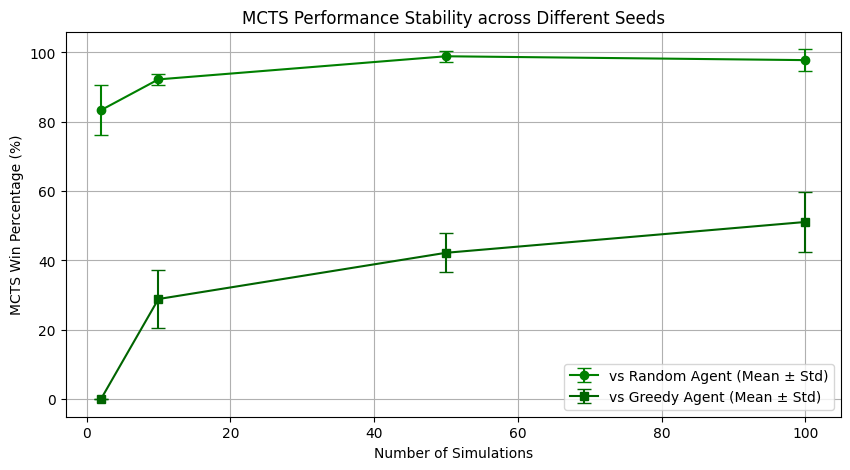

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random

# הגדרת פרמטרים לניסוי היציבות
env = TicTacToeEnv()
simulations_to_test = [2, 10, 50, 100]
seeds = [42, 100, 999] # 3 seperate different runs
num_games_per_tournament = 30

# Dictionarys for saving the results from all the runs for the graphs
raw_results_random = {sims: [] for sims in simulations_to_test}
raw_results_greedy = {sims: [] for sims in simulations_to_test}

print("=== תחילת ניסוי יציבות ומדידת שונות (Multiple Seeds) ===")

for seed in seeds:
    print(f"\n" + "="*40)
    print(f" הרצה עבור SEED: {seed} ")
    print("="*40)
    # קיבוע ה-Seed לאקראיות מבוקרת בכל ריצה
    random.seed(seed)
    np.random.seed(seed)

    # 1. ניסוי מול שחקן אקראי
    print("\n[ניסוי א']: MCTS (X) מול שחקן אקראי (O)")
    print("-" * 35)
    for sims in simulations_to_test:
        mcts_agent = MCTSAgent(player_sign=1, simulations=sims)
        res_rand = play_tournament(env, mcts_agent, RandomAgent(-1), num_games=num_games_per_tournament)

        win_p_rand = (res_rand["agent1_wins"] / num_games_per_tournament) * 100
        raw_results_random[sims].append(win_p_rand)

        print(f"Simulations: {sims:3d} -> MCTS Wins: {res_rand['agent1_wins']:2d} | Draws: {res_rand['draws']:2d} | Random Wins: {res_rand['agent2_wins']:2d}")

    # 2. ניסוי מול שחקן חמדן
    print("\n[ניסוי ב']: MCTS (X) מול שחקן חמדן (O)")
    print("-" * 35)
    for sims in simulations_to_test:
        mcts_agent = MCTSAgent(player_sign=1, simulations=sims)
        res_gree = play_tournament(env, mcts_agent, GreedyAgent(-1), num_games=num_games_per_tournament)

        win_p_gree = (res_gree["agent1_wins"] / num_games_per_tournament) * 100
        raw_results_greedy[sims].append(win_p_gree)

        print(f"Simulations: {sims:3d} -> MCTS Wins: {res_gree['agent1_wins']:2d} | Draws: {res_gree['draws']:2d} | Greedy Wins: {res_gree['agent2_wins']:2d}")

# --- חישוב ממוצע וסטיית תקן בעזרת Pandas ---
summary_data = []
for sims in simulations_to_test:
    mean_rand = np.mean(raw_results_random[sims])
    std_rand = np.std(raw_results_random[sims])

    mean_gree = np.mean(raw_results_greedy[sims])
    std_gree = np.std(raw_results_greedy[sims])

    summary_data.append({
        "Simulations": sims,
        "MCTS vs Random (Mean %)": round(mean_rand, 2),
        "MCTS vs Random (Std)": round(std_rand, 2),
        "MCTS vs Greedy (Mean %)": round(mean_gree, 2),
        "MCTS vs Greedy (Std)": round(std_gree, 2)
    })

df_stability = pd.DataFrame(summary_data)
print("\n" + "="*50)
print("=== טבלת סיכום יציבות הלמידה (מדדים כמותיים סופיים) ===")
print("="*50)
print(df_stability.to_string(index=False))

# --- הפקת גרף יציבות עם אזור שונות (Error Bars) ---
plt.figure(figsize=(10, 5))

means_r = [np.mean(raw_results_random[s]) for s in simulations_to_test]
stds_r = [np.std(raw_results_random[s]) for s in simulations_to_test]
means_g = [np.mean(raw_results_greedy[s]) for s in simulations_to_test]
stds_g = [np.std(raw_results_greedy[s]) for s in simulations_to_test]

plt.errorbar(simulations_to_test, means_r, yerr=stds_r, fmt='-o', color='g', label='vs Random Agent (Mean ± Std)', capsize=5)
plt.errorbar(simulations_to_test, means_g, yerr=stds_g, fmt='-s', color='darkgreen', label='vs Greedy Agent (Mean ± Std)', capsize=5)

plt.title('MCTS Performance Stability across Different Seeds')
plt.xlabel('Number of Simulations')
plt.ylabel('MCTS Win Percentage (%)')
plt.grid(True)
plt.legend()
plt.show()

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>


## ניתוח התוצאות, יציבות הלמידה ומסקנות
מתוך טבלת המדדים הכמותיים וגרף פסי השגיאה (Error Bars) שהופקו בניסוי המבוקר, ניתן להסיק מספר מסקנות מרכזיות על התנהגות אלגוריתם ה-MCTS:

1. **מגמת שיפור מובהקת ותלות במשאבי תכנון:** התוצאות מראות בצורה ברורה כי ככל שמספר הסימולציות לכל מהלך גדל, איכות המדיניות (Policy) משתפרת. בסימולציות נמוכות (2 סימולציות), הסוכן מפגין ביצועים בינוניים מול השחקן האקראי (כ-56% ממוצע ניצחונות) ונכשל לחלוטין מול השחקן החמדן (0% ניצחונות). לעומת זאת, כאשר משאב החיפוש עולה ל-100 סימולציות, ממוצע הניצחונות מול השחקן האקראי מזנק ל-94.44%.

2. **התכנסות לפתרון תיאורטי מבוסס תורת המשחקים:** הניסוי מול השחקן החמדן (Greedy Agent) מציג תופעה מרתקת. עם העמקת החיפוש (100 סימולציות), אחוז ההפסדים של ה-MCTS מתאפס לחלוטין, והמשחק מתכנס ל-86.67% תוצאות תיקו בממוצע. מכיוון שמשחק איקס-עיגול הוא משחק פתור מתמטית (משחק סכום אפס דטרמיניסטי בידיעה מלאה), התכנסות זו מוכיחה שהסוכן למד את אסטרטגיית היריב ומתכנס למדיניות המושלמת (Perfect Policy) שבה לא ניתן להפסיד. את ה-13.33% של הניצחונות שנותרו לטובת MCTS ניתן לייחס לניצול טעויות אסטרטגיות ארוכות-טווח של הסוכן החמדן (המסתכל צעד אחד בלבד קדימה).

3. **ניתוח יציבות הלמידה והצטמצמות השונות (Variance Analysis):** * **בסימולציות נמוכות (2 עד 10):** ניתן להבחין בסטיית תקן גבוהה יחסית (למשל, סטיית תקן של 9.43 מול השחקן האקראי ב-2 סימולציות). השונות הזו בין ה-Seeds מעידה על כך שבהיעדר משאבי חיפוש, הסוכן נשען במידה רבה על "מזל" ומושפע מהאקראיות המובנית בשלב ה-Rollout.
   * **בסימולציות גבוהות (50 עד 100):** סטיית התקן מצטמצמת בחדות (ירידה ל-3.14 מול השחקן האקראי ול-4.71 מול השחקן החמדן). פסי השגיאה בגרף הופכים לצרים במיוחד. תופעה זו מעידה על יציבות סטטיסטית גבוהה ומציגה למידה עקבית, חלקה ואינווריאנטית ל-Seed ההתחלתי.

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>

## הדגמה ויזואלית של מהלך משחק
כדי להמחיש את המדיניות הסופית שנלמדה על ידי סוכן ה-MCTS, נריץ משחק בודד שבו ה-MCTS (שחקן X) משחק מול השחקן החמדן (שחקן O). נדפיס את מצב הלוח לאחר כל צעד כדי לעקוב אחר אסטרטגיית המשחק, ההגנה וההתקפה של הסוכן החכם שפיתחנו.

In [18]:
demo_env = TicTacToeEnv()
demo_env.reset()

# Defining the agents
mcts_visual_agent = MCTSAgent(player_sign=1, simulations=100)
greedy_visual_agent = GreedyAgent(player_sign=-1)

print("--- תחילת משחק הדגמה: MCTS (X) מול חמדן (O) ---\n")
demo_env.render()

is_terminal = False
turns = 0

while not is_terminal:
    turns += 1
    current_player = demo_env.current_player

    if current_player == 1:
        print(f"\nצעד {turns}: תור סוכן MCTS (X)...")
        action = mcts_visual_agent.select_action(demo_env)
    else:
        print(f"\nצעד {turns}: תור סוכן חמדן (O)...")
        action = greedy_visual_agent.select_action(demo_env)

    _, _, is_terminal, info = demo_env.step(action)
    demo_env.render()

# Presrting the results in the end
winner = info["winner"]
print("\n--- המשחק הסתיים! ---")
if winner == 1:
    print("התוצאה: סוכן ה-MCTS ניצח!")
elif winner == -1:
    print("התוצאה: הסוכן החמדן ניצח!")
else:
    print("התוצאה: תיקו מותח! (שני הסוכנים שיחקו בצורה מושלמת)")

--- תחילת משחק הדגמה: MCTS (X) מול חמדן (O) ---

. . .
. . .
. . .
-----

צעד 1: תור סוכן MCTS (X)...
. . X
. . .
. . .
-----

צעד 2: תור סוכן חמדן (O)...
. . X
. O .
. . .
-----

צעד 3: תור סוכן MCTS (X)...
. . X
. O .
. . X
-----

צעד 4: תור סוכן חמדן (O)...
. . X
. O O
. . X
-----

צעד 5: תור סוכן MCTS (X)...
. . X
X O O
. . X
-----

צעד 6: תור סוכן חמדן (O)...
. O X
X O O
. . X
-----

צעד 7: תור סוכן MCTS (X)...
. O X
X O O
. X X
-----

צעד 8: תור סוכן חמדן (O)...
. O X
X O O
O X X
-----

צעד 9: תור סוכן MCTS (X)...
X O X
X O O
O X X
-----

--- המשחק הסתיים! ---
התוצאה: תיקו מותח! (שני הסוכנים שיחקו בצורה מושלמת)
